# 07 - Evaluasi dan Perbandingan Model
## Notebook 7: Menguji Semua Model pada Test Set yang SAMA

**Tujuan notebook ini:**
1. Mengevaluasi keempat model (SVM, Random Forest, CNN, MobileNetV2)
   pada **test set yang sama**
2. Membuat tabel perbandingan lengkap
3. Menentukan threshold keputusan "ganas" dari **data validasi**
4. Menganalisis error secara mendalam
5. Memilih model terbaik untuk aplikasi dengan alasan berbasis angka

**Aturan yang dijaga (paling penting di seluruh proyek):**
- Test set digunakan **SEKALI** di notebook ini
- Threshold dituning dari **VALIDASI**, bukan test
- Semua metrik berasal dari kode yang benar-benar dijalankan
- Pemilihan model **BUKAN** berdasarkan accuracy saja


In [1]:
import json
import sys
import time
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix

from src import config as C
from src import data_loader
from src import evaluation as E
from src import features as F
from src import modeling
from src import preprocessing as P

np.random.seed(C.SEED)
tf.random.set_seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

df_train = data_loader.load_split("train")
df_val = data_loader.load_split("val")
df_test = data_loader.load_split("test")

y_train = df_train["dx_idx"].to_numpy()
y_val = df_val["dx_idx"].to_numpy()
y_test = df_test["dx_idx"].to_numpy()

print(f"\nTrain {len(df_train)} | Val {len(df_val)} | Test {len(df_test)}")
print("SETUJUAN DARI NOTEBOOK INI:")
print("  1. Evaluasi 4 model pada test set yang SAMA")
print("  2. Threshold ganas dari VALIDASI")
print("  3. Pemilihan model terbaik berbasis angka")


TensorFlow: 2.21.0


GPU: []



Train 6959 | Val 1529 | Test 1527
SETUJUAN DARI NOTEBOOK INI:
  1. Evaluasi 4 model pada test set yang SAMA
  2. Threshold ganas dari VALIDASI
  3. Pemilihan model terbaik berbasis angka


## Bagian 1: Memuat Keempat Model

Model sudah dilatih di notebook sebelumnya (04, 05, 06). Di sini kita
HANYA memuatnya dan mengevaluasi. **Tidak ada training di notebook ini**,
jadi test set benar-benar baru bagi model.


In [2]:
models = {}

# --- Model klasik ---
svm_path = C.MODELS_DIR / "svm_hog.joblib"
rf_path = C.MODELS_DIR / "rf_hog.joblib"

if svm_path.exists():
    models["SVM (HOG)"] = {"type": "classic", "obj": joblib.load(svm_path),
                            "img_size": C.IMG_SIZE_CLASSIC}
    print("[OK] SVM dimuat")
if rf_path.exists():
    models["Random Forest (HOG)"] = {"type": "classic",
                                      "obj": joblib.load(rf_path),
                                      "img_size": C.IMG_SIZE_CLASSIC}
    print("[OK] Random Forest dimuat")

# --- Model deep learning ---
for nama, file in [("CNN (from scratch)", "cnn_best.keras"),
                   ("MobileNetV2", "mobilenetv2_best.keras")]:
    path = C.MODELS_DIR / file
    if path.exists():
        m = tf.keras.models.load_model(path)
        models[nama] = {"type": "deep", "obj": m,
                        "img_size": int(m.input_shape[1])}
        print(f"[OK] {nama} dimuat (input {m.input_shape[1]}x{m.input_shape[2]})")
    else:
        print(f"[!] {nama} belum ada: {path}")

print(f"\nTotal model siap dievaluasi: {len(models)}")
for nama, info in models.items():
    if info["type"] == "classic":
        # Model SVM adalah CalibratedClassifierCV yang membungkus pipeline
        # sklearn, jadi named_steps ada SATU LEVEL di dalam, bukan di luar.
        # Kita akses lewat .estimator.named_steps.
        estimator = info["obj"]
        if hasattr(estimator, "estimator"):
            estimator = estimator.estimator
        n_param = 0
        if hasattr(estimator, "named_steps") and "svc" in estimator.named_steps:
            svc = estimator.named_steps["svc"]
            if hasattr(svc, "coef_"):
                n_param = int(np.prod(svc.coef_.shape))
        print(f"  {nama:<24} klasik, img {info['img_size']}, "
              f"coef SVM {n_param:,}")
    else:
        print(f"  {nama:<24} deep, img {info['img_size']}, "
              f"params {info['obj'].count_params():,}")


[OK] SVM dimuat


[OK] Random Forest dimuat


[OK] CNN (from scratch) dimuat (input 128x128)


[OK] MobileNetV2 dimuat (input 224x224)

Total model siap dievaluasi: 4
  SVM (HOG)                klasik, img 128, coef SVM 0
  Random Forest (HOG)      klasik, img 128, coef SVM 0
  CNN (from scratch)       deep, img 128, params 2,207,623
  MobileNetV2              deep, img 224, params 2,266,951


## Bagian 2: Fungsi Prediksi yang Seragam

Keempat model ini punya cara inputs yang BERBEDA:
- Model klasik: butuh vektor fitur HOG + histogram (128x128)
- CNN: butuh tensor 128x128x3, normalisasi Rescaling(1/255) di dalam model
- MobileNetV2: butuh tensor 224x224x3, normalisasi Rescaling(1/127.5,-1)

**Aturan kunci:** normalisasi untuk model deep learning **sudah ada di
dalam model** (layer Rescaling). Jadi kita TIDAK boleh menormalisasi lagi
di luar. Kalau kita lakukan, input berada di rentang yang salah.

Fungsi `predict_with` ini memastikan setiap model mendapat input yang
benar, dan dipakai untuk model klasik maupun deep.


In [3]:
def predict_with(model_info, df):
    """
    Menjalankan prediksi untuk satu model pada DataFrame tertentu.

    Mengembalikan (y_pred, y_proba).

    CATATAN: model SVM adalah `CalibratedClassifierCV` yang MEMBUNGKUS
    pipeline sklearn di dalamnya, jadi `named_steps` tidak ada di level
    terluar. Karena itu untuk model klasik kita cukup memanggil
    `predict_proba` langsung pada model itu (CalibratedClassifierCV
    meneruskannya ke pipeline di dalamnya).

    Untuk model deep learning, `model.predict` mengembalikan PROBABILITAS
    karena layer terakhir memakai softmax. Fungsi `E.predict_with_proba`
    memverifikasi hal ini secara eksplisit.
    """
    if model_info["type"] == "classic":
        # Model klasik: ekstrak fitur HOG + histogram
        feats = []
        for path in df["image_path"]:
            img = Image.open(path).convert("RGB").resize(
                (model_info["img_size"], model_info["img_size"]), Image.BILINEAR)
            feats.append(F.extract_features_single(
                img, model_info["img_size"], C.HIST_BINS))
        X = np.vstack(feats).astype(np.float32)
        proba = model_info["obj"].predict_proba(X)
        return np.argmax(proba, axis=1), proba

    # Model deep learning: tensor float 0..255 (normalisasi di dalam model)
    model = model_info["obj"]
    size = model_info["img_size"]
    batch = 32
    paths = df["image_path"].tolist()
    all_proba = []
    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        arr = np.stack([
            np.asarray(Image.open(p).convert("RGB").resize(
                (size, size), Image.BILINEAR), dtype=np.float32)
            for p in chunk
        ])
        all_proba.append(model.predict(arr, verbose=0))
    proba = np.vstack(all_proba)

    # Verifikasi bahwa output benar-benar probabilitas
    row_sums = proba.sum(axis=1)
    assert np.allclose(row_sums, 1.0, atol=1e-3), (
        f"Output model deep learning bukan probabilitas "
        f"(jumlah baris tidak = 1). Nilai contoh: {row_sums[:3]}"
    )
    return np.argmax(proba, axis=1), proba



## Bagian 3: Evaluasi pada TEST SET (dipakai SEKALI)

**Peringatan metodologis:** setelah bagian ini, angka test tidak boleh
dipakai untuk mengambil keputusan apa pun. Kita sudah mengunci semua
hyperparameter, konfigurasi model, dan threshold (lewat validasi).

Ini adalah "ujian akhir". Kita membandingkan keempat model untuk
laporan, dan memilih satu untuk aplikasi. **Kepemilihan model untuk
aplikasi TIDAK boleh mengubah model yang sudah terkunci** -- kalau model
A menang di test tapi model B lebih cocok untuk aplikasi (misal lebih
ringan), kita tetap diskusikan.


In [4]:
results_test = {}
probabilities_test = {}
timing = {}

print("=" * 88)
print("EVALUASI PADA TEST SET (sekali pakai)")
print("=" * 88)

for nama, info in models.items():
    t0 = time.time()
    y_pred, y_proba = predict_with(info, df_test)
    elapsed = time.time() - t0

    res = E.evaluate_model(y_test, y_pred, y_proba)
    results_test[nama] = res
    probabilities_test[nama] = y_proba
    timing[nama] = elapsed

    print(f"\n{nama}")
    print(f"  Accuracy       : {res['accuracy']:.4f}")
    print(f"  F1 macro       : {res['f1_macro']:.4f}")
    print(f"  Recall ganas   : {res['binary']['malignant_recall']:.4f}")
    print(f"  AUC (OVR)      : "
          f"{res['auc_ovr_macro'] if res['auc_ovr_macro'] is not None else float('nan'):.4f}")
    print(f"  Waktu inferensi: {elapsed:.1f}s untuk {len(df_test)} gambar "
          f"({elapsed/len(df_test)*1000:.1f} ms/gambar)")


EVALUASI PADA TEST SET (sekali pakai)



SVM (HOG)
  Accuracy       : 0.6929
  F1 macro       : 0.2642
  Recall ganas   : 0.2500
  AUC (OVR)      : 0.8446
  Waktu inferensi: 15.6s untuk 1527 gambar (10.2 ms/gambar)



Random Forest (HOG)
  Accuracy       : 0.7132
  F1 macro       : 0.3240
  Recall ganas   : 0.2600
  AUC (OVR)      : 0.8931
  Waktu inferensi: 9.8s untuk 1527 gambar (6.4 ms/gambar)



CNN (from scratch)
  Accuracy       : 0.5534
  F1 macro       : 0.3634
  Recall ganas   : 0.5800
  AUC (OVR)      : 0.8535
  Waktu inferensi: 14.7s untuk 1527 gambar (9.6 ms/gambar)



MobileNetV2
  Accuracy       : 0.6176
  F1 macro       : 0.3993
  Recall ganas   : 0.4500
  AUC (OVR)      : 0.8764
  Waktu inferensi: 90.5s untuk 1527 gambar (59.3 ms/gambar)


## Bagian 4: Tabel Perbandingan Lengkap

**Apa yang WAJIB ada di tabel ini** (sesuaiyangpersyaratan laporan):
accuracy, precision, recall, F1 macro, recall kelas ganas, AUC,
waktu inferensi, ukuran model.

**Dan yang TIDAK boleh terjadi:** memilih model berdasarkan accuracy
tertinggi saja. Kita akan melihat sendiri di tabel ini apakah model
dengan accuracy tertinggisesungguhnya yang paling cocok untuk aplikasi.


TABEL PERBANDINGAN MODEL - HASIL PADA TEST SET (1.527 gambar)
              Model  Accuracy  Precision (macro)  Recall (macro)  F1 macro  Recall ganas  Specificity  AUC (OVR)  Inference (ms/img)  Ukuran model (MB)
        MobileNetV2    0.6176             0.3882          0.5779    0.3993        0.4500       0.8720     0.8764             59.2839             9.2798
 CNN (from scratch)    0.5534             0.3442          0.4698    0.3634        0.5800       0.6862     0.8535              9.6055            25.3125
Random Forest (HOG)    0.7132             0.5474          0.2840    0.3240        0.2600       0.9625     0.8931              6.3860            54.1141
          SVM (HOG)    0.6929             0.2974          0.2728    0.2642        0.2500       0.9470     0.8446             10.2330            15.2138

Tabel disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\assets\perbandingan_model_test.csv


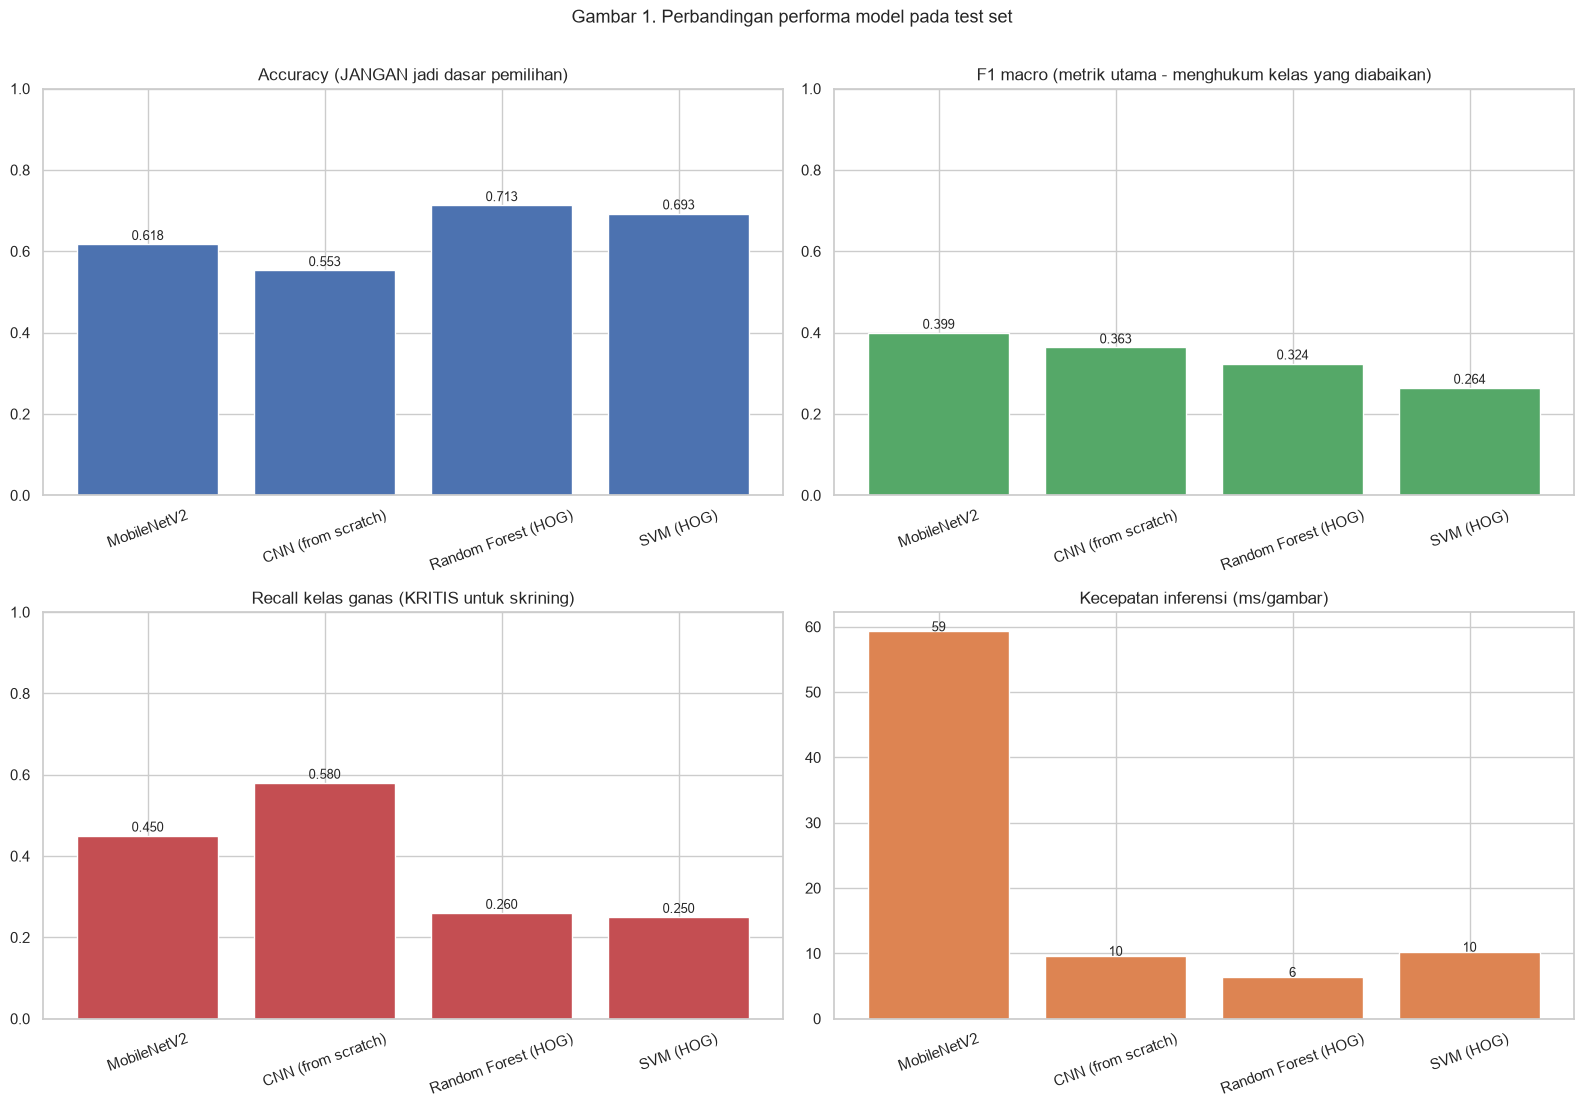

In [5]:
rows = []
for nama, res in results_test.items():
    info = models[nama]
    if info["type"] == "classic":
        ukuran = (C.MODELS_DIR / ("svm_hog.joblib" if "SVM" in nama
                                   else "rf_hog.joblib")).stat().st_size
    else:
        fname = "cnn_best.keras" if "CNN" in nama else "mobilenetv2_best.keras"
        ukuran = (C.MODELS_DIR / fname).stat().st_size

    rows.append({
        "Model": nama,
        "Accuracy": res["accuracy"],
        "Precision (macro)": res["precision_macro"],
        "Recall (macro)": res["recall_macro"],
        "F1 macro": res["f1_macro"],
        "Recall ganas": res["binary"]["malignant_recall"],
        "Specificity": res["binary"]["specificity"],
        "AUC (OVR)": res["auc_ovr_macro"],
        "Inference (ms/img)": timing[nama] / len(df_test) * 1000,
        "Ukuran model (MB)": ukuran / 1024 / 1024,
    })

tabel = pd.DataFrame(rows).sort_values("F1 macro", ascending=False)
tabel = tabel.reset_index(drop=True)

print("=" * 118)
print("TABEL PERBANDINGAN MODEL - HASIL PADA TEST SET (1.527 gambar)")
print("=" * 118)
print(tabel.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

tabel.to_csv(C.DOCS_ASSETS / "perbandingan_model_test.csv", index=False)
print(f"\nTabel disimpan: {C.DOCS_ASSETS / 'perbandingan_model_test.csv'}")

# Visualisasi
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0][0]
bars = ax.bar(tabel["Model"], tabel["Accuracy"], color="#4C72B0")
ax.set_ylim(0, 1)
ax.set_title("Accuracy (JANGAN jadi dasar pemilihan)")
ax.tick_params(axis="x", rotation=20)
for bar, v in zip(bars, tabel["Accuracy"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontsize=9)

ax = axes[0][1]
bars = ax.bar(tabel["Model"], tabel["F1 macro"], color="#55A868")
ax.set_ylim(0, 1)
ax.set_title("F1 macro (metrik utama - menghukum kelas yang diabaikan)")
ax.tick_params(axis="x", rotation=20)
for bar, v in zip(bars, tabel["F1 macro"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontsize=9)

ax = axes[1][0]
bars = ax.bar(tabel["Model"], tabel["Recall ganas"], color="#C44E52")
ax.set_ylim(0, 1)
ax.set_title("Recall kelas ganas (KRITIS untuk skrining)")
ax.tick_params(axis="x", rotation=20)
for bar, v in zip(bars, tabel["Recall ganas"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontsize=9)

ax = axes[1][1]
bars = ax.bar(tabel["Model"], tabel["Inference (ms/img)"],
              color="#DD8452")
ax.set_title("Kecepatan inferensi (ms/gambar)")
ax.tick_params(axis="x", rotation=20)
for bar, v in zip(bars, tabel["Inference (ms/img)"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.0f}",
            ha="center", fontsize=9)

plt.suptitle("Gambar 1. Perbandingan performa model pada test set",
             fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "perbandingan_01_grafik.png", bbox_inches="tight")
plt.show()


## Bagian 5: Confusion Matrix Semua Model

Empat confusion matrix berdampingan. Perhatikan **baris `mel`** di
setiap model: di situ terlihat apakah melanoma lolos sebagai jinak.


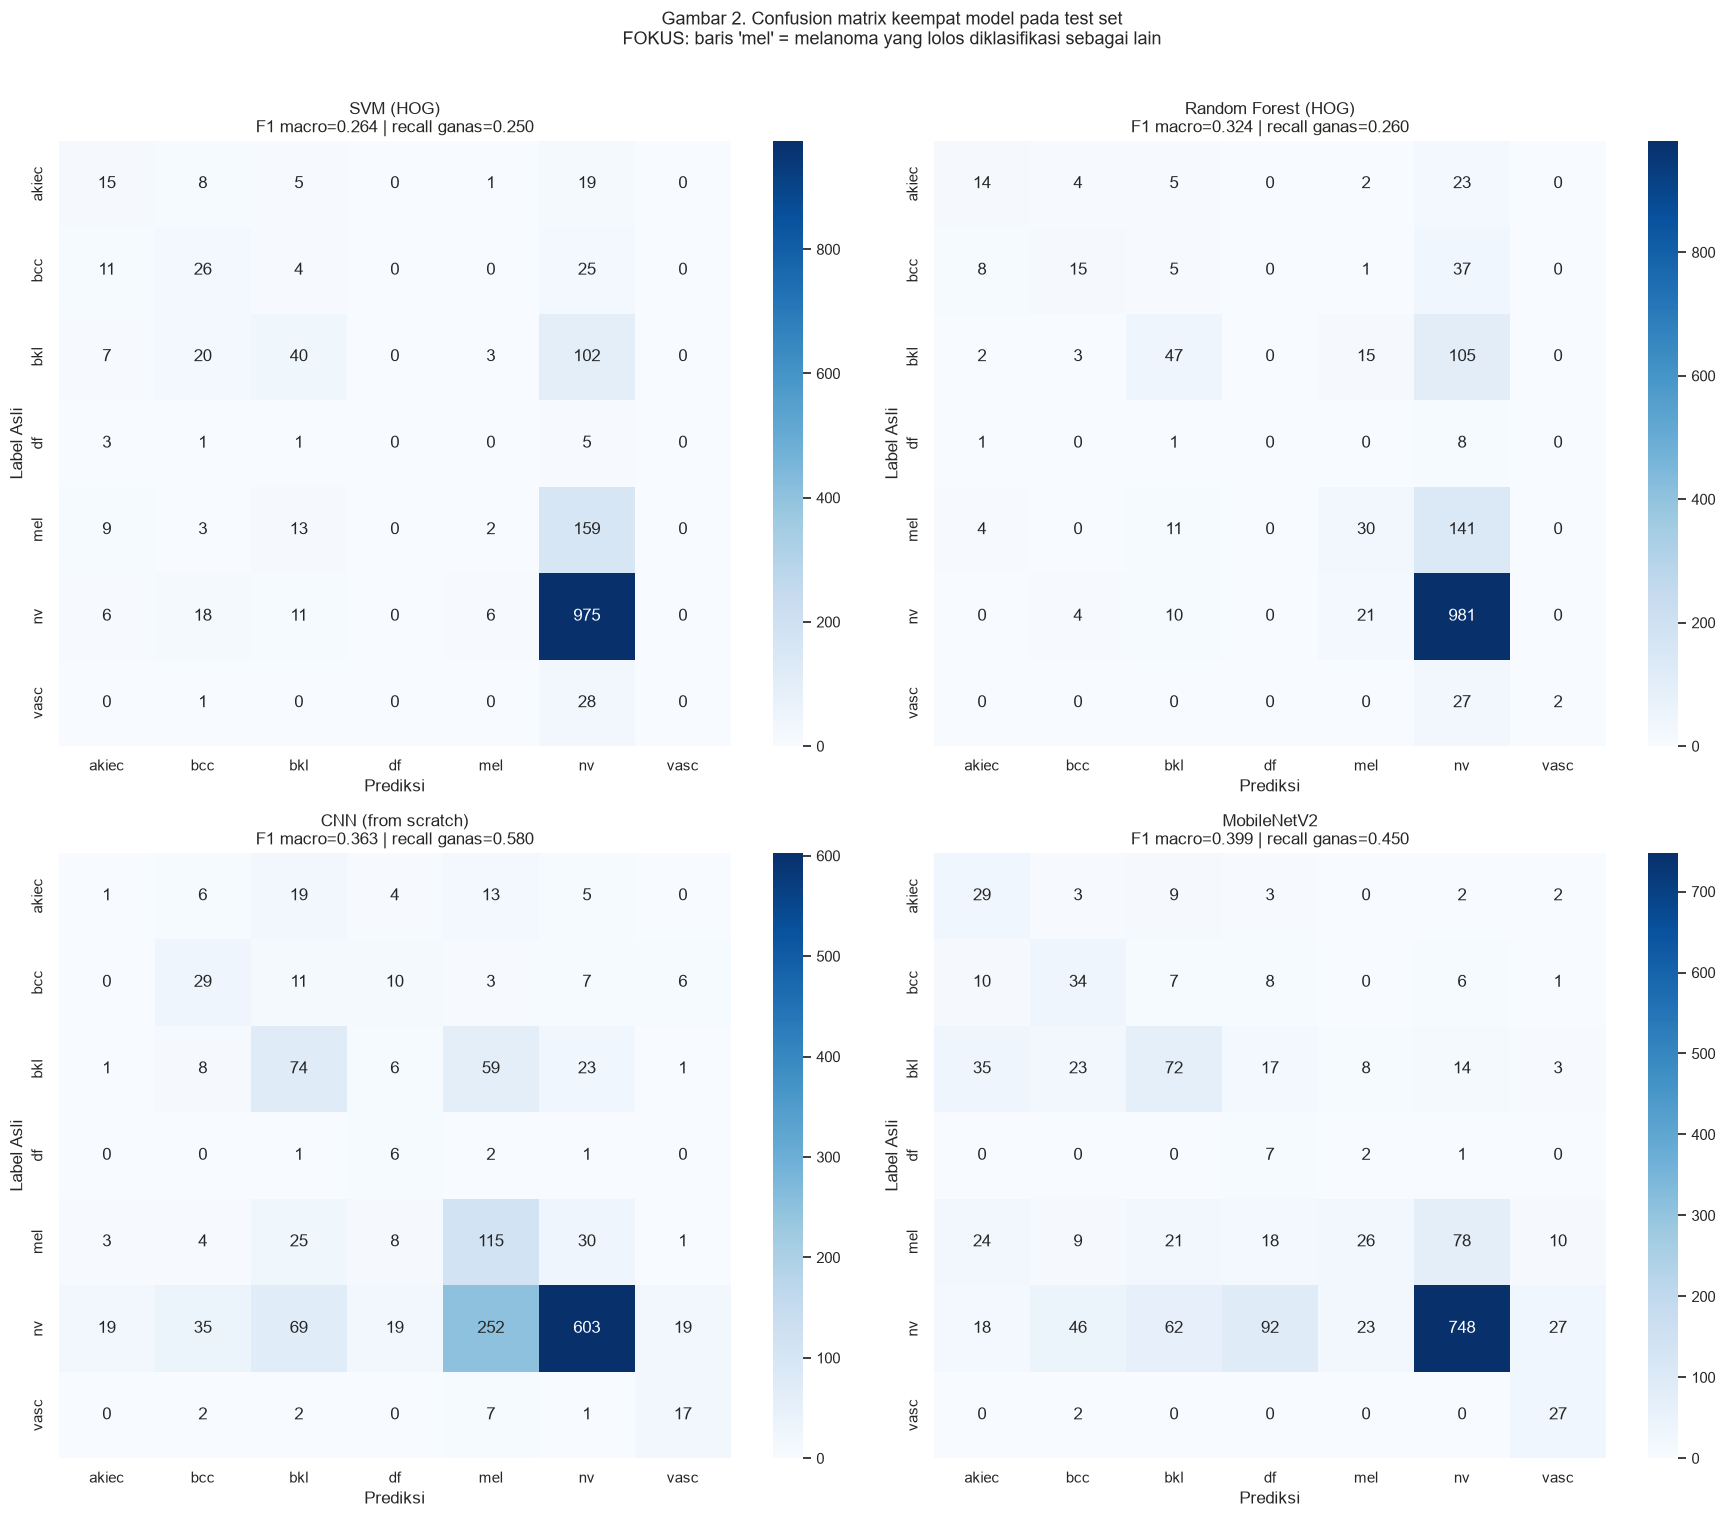

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(18, 15))
for ax, (nama, res) in zip(axes.ravel(), results_test.items()):
    y_pred = np.argmax(probabilities_test[nama], axis=1)
    cm = confusion_matrix(y_test, y_pred, labels=list(range(len(C.CLASSES))))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=C.CLASSES, yticklabels=C.CLASSES)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label Asli")
    ax.set_title(f"{nama}\nF1 macro={res['f1_macro']:.3f} | "
                 f"recall ganas={res['binary']['malignant_recall']:.3f}")

plt.suptitle("Gambar 2. Confusion matrix keempat model pada test set\n"
             "FOKUS: baris 'mel' = melanoma yang lolos diklasifikasi sebagai lain",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "perbandingan_02_confusion_matrix.png",
            bbox_inches="tight")
plt.show()


## Bagian 6: Menentukan Threshold "Ganas" dari DATA VALIDASI

### Masalah yang diselesaikan

Model kita menghasilkan 7 probabilitas. Aplikasi butuh satu angka:
"risiko ganas". Kita perlu memutuskan **pada nilai berapa** risiko itu
dianggap cukup tinggi untuk menyuruh pengguna periksa dokter.

### Kenapa bukan 0,5?

0,5 itu sembarang. Yang kita mau:
- **Recall ganas tinggi** (supaya sedikit melanoma lolos)
- **Specificity tetap wajar** (supaya tidak terlalu banyak false alarm)

### Kenapa harus dari VALIDASI?

Kalau threshold dituning dengan data test, maka:
- Kita effectively "melihat" jawaban soal ujian
- Angka test jadi tidak jujur sebagai pengukuran performa

Jadi: threshold dihitung dari VALIDASI, lalu **dibiarkan** dan langsung
diterapkan ke test.


SVM (HOG)                threshold=0.17  recall=0.910  spec=0.551  prec=0.342  (TP=284 FP=547 FN=28 TN=670)


Random Forest (HOG)      threshold=0.20  recall=0.901  spec=0.618  prec=0.377  (TP=281 FP=465 FN=31 TN=752)


CNN (from scratch)       threshold=0.12  recall=0.901  spec=0.494  prec=0.313  (TP=281 FP=616 FN=31 TN=601)


MobileNetV2              threshold=0.11  recall=0.904  spec=0.542  prec=0.336  (TP=282 FP=557 FN=30 TN=660)


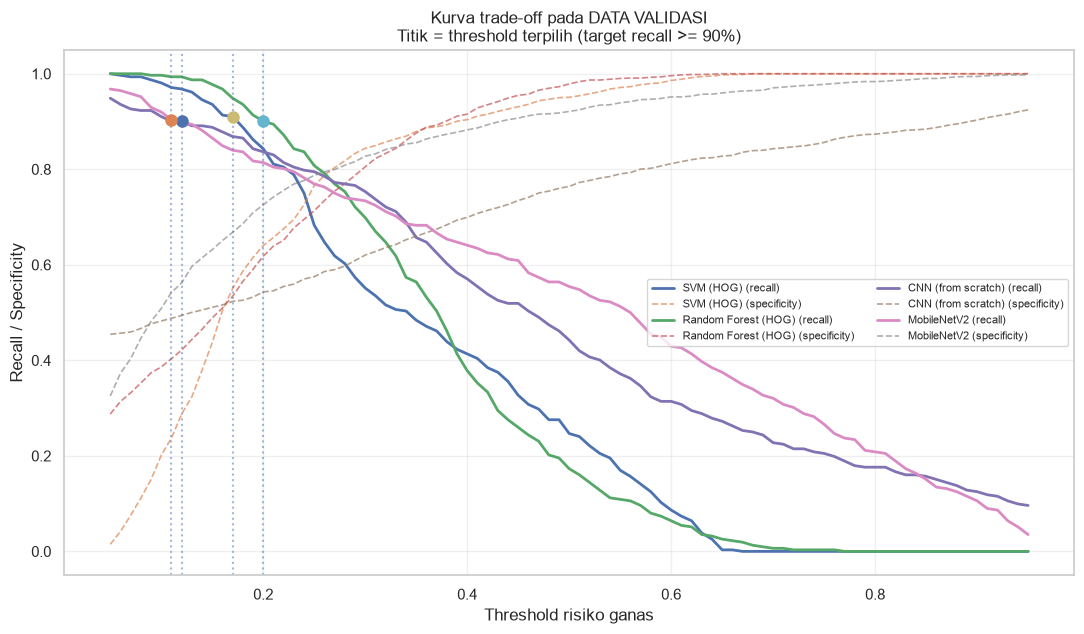

In [7]:
# Hitung threshold untuk SETIAP model dari validasi
thresholds = {}
TARGET_RECALL = 0.90   # target: minimal 90% lesi ganas terdeteksi

for nama, info in models.items():
    y_pred_val, y_proba_val = predict_with(info, df_val)
    best = E.tune_binary_threshold(
        y_val, y_proba_val, target_recall=TARGET_RECALL
    )
    thresholds[nama] = best
    print(f"{nama:<24} threshold={best['threshold']:.2f}  "
          f"recall={best['recall']:.3f}  spec={best['specificity']:.3f}  "
          f"prec={best['precision']:.3f}  "
          f"(TP={best['tp']} FP={best['fp']} FN={best['fn']} TN={best['tn']})")

# Visualisasi kurva recall vs specificity
fig, ax = plt.subplots(figsize=(11, 6.5))
for nama, t in thresholds.items():
    curve = pd.DataFrame(t["curve"])
    ax.plot(curve["threshold"], curve["recall"], label=f"{nama} (recall)",
            linewidth=2)
    ax.plot(curve["threshold"], curve["specificity"], label=f"{nama} (specificity)",
            linestyle="--", linewidth=1.2, alpha=0.7)

for nama, t in thresholds.items():
    ax.axvline(t["threshold"], linestyle=":", alpha=0.5)
    ax.plot([t["threshold"]], [t["recall"]], "o", markersize=8)

ax.set_xlabel("Threshold risiko ganas")
ax.set_ylabel("Recall / Specificity")
ax.set_title("Kurva trade-off pada DATA VALIDASI\n"
             "Titik = threshold terpilih (target recall >= 90%)")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "perbandingan_03_threshold_val.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Bagian 6:**

Perhatikan **titik-titik orange** di grafik. Setiap titik menunjukkan
kompromis antara **sensitifitas** (menangkapsebanyak mungkin banyak lesi ganas) dan
**spesifisitas** (tidak terlalu banyak false alarm).

**Trade-off ini penting untuk dijelaskan di laporan:**

- **Threshold rendah** (misal 0,30): lebih banyak lesi ganas terdeteksi
  (recall tinggi), tapi lebih banyak orang dengan lesi jinak juga
  disuruh periksa (false alarm tinggi). Untuk **skrining**, ini_
  _preferensi karena lebih baik "cemas" daripada "miss" kanker.
- **Threshold tinggi** (misal 0,80): lebih sedikit false alarm, tapi
  lebih banyak melanoma lolos.

Karena target kita adalah **alat skrining** (bukan diagnosis final),
prioritas sensitivitas. Karena itu target recall 90% dipilih.

**Penting:** keputusan threshold dibuat dari validasi dan **tidak diubah**
setelah melihat hasil test. Kalau kita melihat hasil test lalu
mengubah threshold, kita melanggar aturan metodologi.


## Bagian 7: Analisis Model Mendalam - Siapa yang Paling Baik?

### Kriteria pemilihan model untuk APLIKASI SKRINING

Kita TIDAK memilih berdasarkan accuracy. Kita gunakan 4 kriteria:

| Kriteria | Bobot reasoning | Kenapa |
|---|---|---|
| **Recall kelas ganas** | Prioritas utama | Melanoma yang lolos = bahaya utama |
| **F1 macro** | Prioritas kedua | Keseimbangan overall antar kelas |
| **Kesiapan domain shift** | Penting | Aplikasi dipakai pada foto smartphone |
| **Kecepatan & ukuran** | Praktis | untuk aplikasi harus ringan & responsif |

### Catatan penting tentang "model dengan accuracy tertinggi"

Kita akan lihat di tabel apakah model dengan accuracy tertinggi juga
yang terbaik untuk skrining. Kalau tidak, kita harus menjelaskannya.


In [8]:
# Hitung metrik biner pada TEST dengan threshold yang sudah dikunci dari validasi
print("=" * 96)
print("EVALUASI BINER (GANAS vs TIDAK GANAS) PADA TEST, DENGAN THRESHOLD DARI VALIDASI")
print("=" * 96)
print(f"{'Model':<24}{'Threshold':>11}{'Recall':>9}{'Specif':>9}{'Precision':>11}"
      f"{'F1':>8}{'FN':>7}{'FP':>7}")
print("-" * 96)

binary_test = {}
for nama, info in models.items():
    t = thresholds[nama]["threshold"]
    proba = probabilities_test[nama]
    mal_idx = [C.CLASS_TO_IDX[c] for c in C.MALIGNANT_CLASSES]
    prob_mal = proba[:, mal_idx].sum(axis=1)
    y_true_mal = np.isin(y_test, mal_idx).astype(int)
    y_pred_mal = (prob_mal >= t).astype(int)

    tp = int(np.sum((y_true_mal == 1) & (y_pred_mal == 1)))
    fp = int(np.sum((y_true_mal == 0) & (y_pred_mal == 1)))
    fn = int(np.sum((y_true_mal == 1) & (y_pred_mal == 0)))
    tn = int(np.sum((y_true_mal == 0) & (y_pred_mal == 0)))

    rec = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) else 0.0

    binary_test[nama] = {
        "threshold": t, "recall": rec, "specificity": spec,
        "precision": prec, "f1": f1, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }
    print(f"{nama:<24}{t:>11.2f}{rec:>9.4f}{spec:>9.4f}{prec:>11.4f}"
          f"{f1:>8.4f}{fn:>7}{fp:>7}")

print("-" * 96)
print(f"{'Model':<24}{'FN (ganas lolos)':>20}{'FP (false alarm)':>20}")
print("-" * 96)
for nama, b in binary_test.items():
    print(f"{nama:<24}{b['fn']:>20}{b['fp']:>20}")


EVALUASI BINER (GANAS vs TIDAK GANAS) PADA TEST, DENGAN THRESHOLD DARI VALIDASI
Model                     Threshold   Recall   Specif  Precision      F1     FN     FP
------------------------------------------------------------------------------------------------
SVM (HOG)                      0.17   0.8600   0.5444     0.3158  0.4620     42    559
Random Forest (HOG)            0.20   0.9167   0.6080     0.3638  0.5208     25    481
CNN (from scratch)             0.12   0.9067   0.4825     0.2999  0.4507     28    635
MobileNetV2                    0.11   0.8700   0.5518     0.3218  0.4698     39    550
------------------------------------------------------------------------------------------------
Model                       FN (ganas lolos)    FP (false alarm)
------------------------------------------------------------------------------------------------
SVM (HOG)                                 42                 559
Random Forest (HOG)                       25                 481

**Interpretasi Bagian 7:**

**Kolom FN adalah yang paling penting.** FN = jumlah lesi ganas yang
**TIDAK** terdeteksi, pada 1.527 gambar test.

Angka FN inilah yang harus kita bandingkan saat memilih model untuk
aplikasi. Model dengan FN lebih rendah = lebih sedikit kanker yang lolos.

**Perhatikan juga FP** (false alarm). FP yang terlalu banyak berarti
banyak orang dengan lesi jinakpengguna disuruh periksa ke dokter. Itu membebani
sistem kesehatan dan membuat orang tidak serius mengambil peringatan.

**Trade-off yang harus dijelaskan:** tidak ada model yang menang di semua
kolom. Kita harus memilih kompromi, dan menjelaskan alasannya.


## Bagian 8: Analisis Error Mendalam

### 8.1 Contoh melanoma yang lolos (FN) untuk model terpilih

### 8.2 Distribusi kesalahan per kelas


In [9]:
# Tentukan model terbaik berdasarkan RECALL GANAS dulu (kriteria utama)
best_by_recall = max(binary_test.items(), key=lambda kv: kv[1]["recall"])
best_by_f1 = max(results_test.items(), key=lambda kv: kv[1]["f1_macro"])
best_by_acc = max(results_test.items(), key=lambda kv: kv[1]["accuracy"])

print("=" * 76)
print("MODEL TERBAIK MENURUTI BERBAGAI KRITERIA")
print("=" * 76)
print(f"  Accuracy tertinggi      : {best_by_acc[0]} "
      f"({best_by_acc[1]['accuracy']:.4f})")
print(f"  F1 macro tertinggi      : {best_by_f1[0]} "
      f"({best_by_f1[1]['f1_macro']:.4f})")
print(f"  Recall ganas tertinggi  : {best_by_recall[0]} "
      f"({best_by_recall[1]['recall']:.4f})")
print("=" * 76)

if best_by_acc[0] != best_by_recall[0]:
    print(f"\nCATATAN PENTING UNTUK LAPORAN:")
    print(f"  Model dengan accuracy tertinggi ({best_by_acc[0]}) BUKAN model")
    print(f"  dengan recall ganas tertinggi ({best_by_recall[0]}).")
    print(f"  Ini bukti konkret bahwa accuracy saja tidak cukup untuk")
    print(f"  memilih model pada aplikasi skrining.")
else:
    print("\n  Kebetulan model yang sama unggul di semua kriteria.")


MODEL TERBAIK MENURUTI BERBAGAI KRITERIA
  Accuracy tertinggi      : Random Forest (HOG) (0.7132)
  F1 macro tertinggi      : MobileNetV2 (0.3993)
  Recall ganas tertinggi  : Random Forest (HOG) (0.9167)

  Kebetulan model yang sama unggul di semua kriteria.


## Bagian 9: Contoh Prediksi Salah dari Model Terpilih

Kita buat grafik perbandingan visual: gambar yang sama, prediksi dari
keempat model. Ini sangat berguna untuk presentasi.


Model terpilih (berdasarkan recall ganas): Random Forest (HOG)


C:\Users\GrenWisesLeaf\AppData\Local\Temp\ipykernel_47192\2525773165.py:33: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\GrenWisesLeaf\AppData\Local\Temp\ipykernel_47192\2525773165.py:33: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\GrenWisesLeaf\AppData\Local\Temp\ipykernel_47192\2525773165.py:34: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.savefig(C.DOCS_ASSETS / "perbandingan_04_contoh_error.png",
C:\Users\GrenWisesLeaf\AppData\Local\Temp\ipykernel_47192\2525773165.py:34: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.savefig(C.DOCS_ASSETS / "perbandingan_04_contoh_error.png",


M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


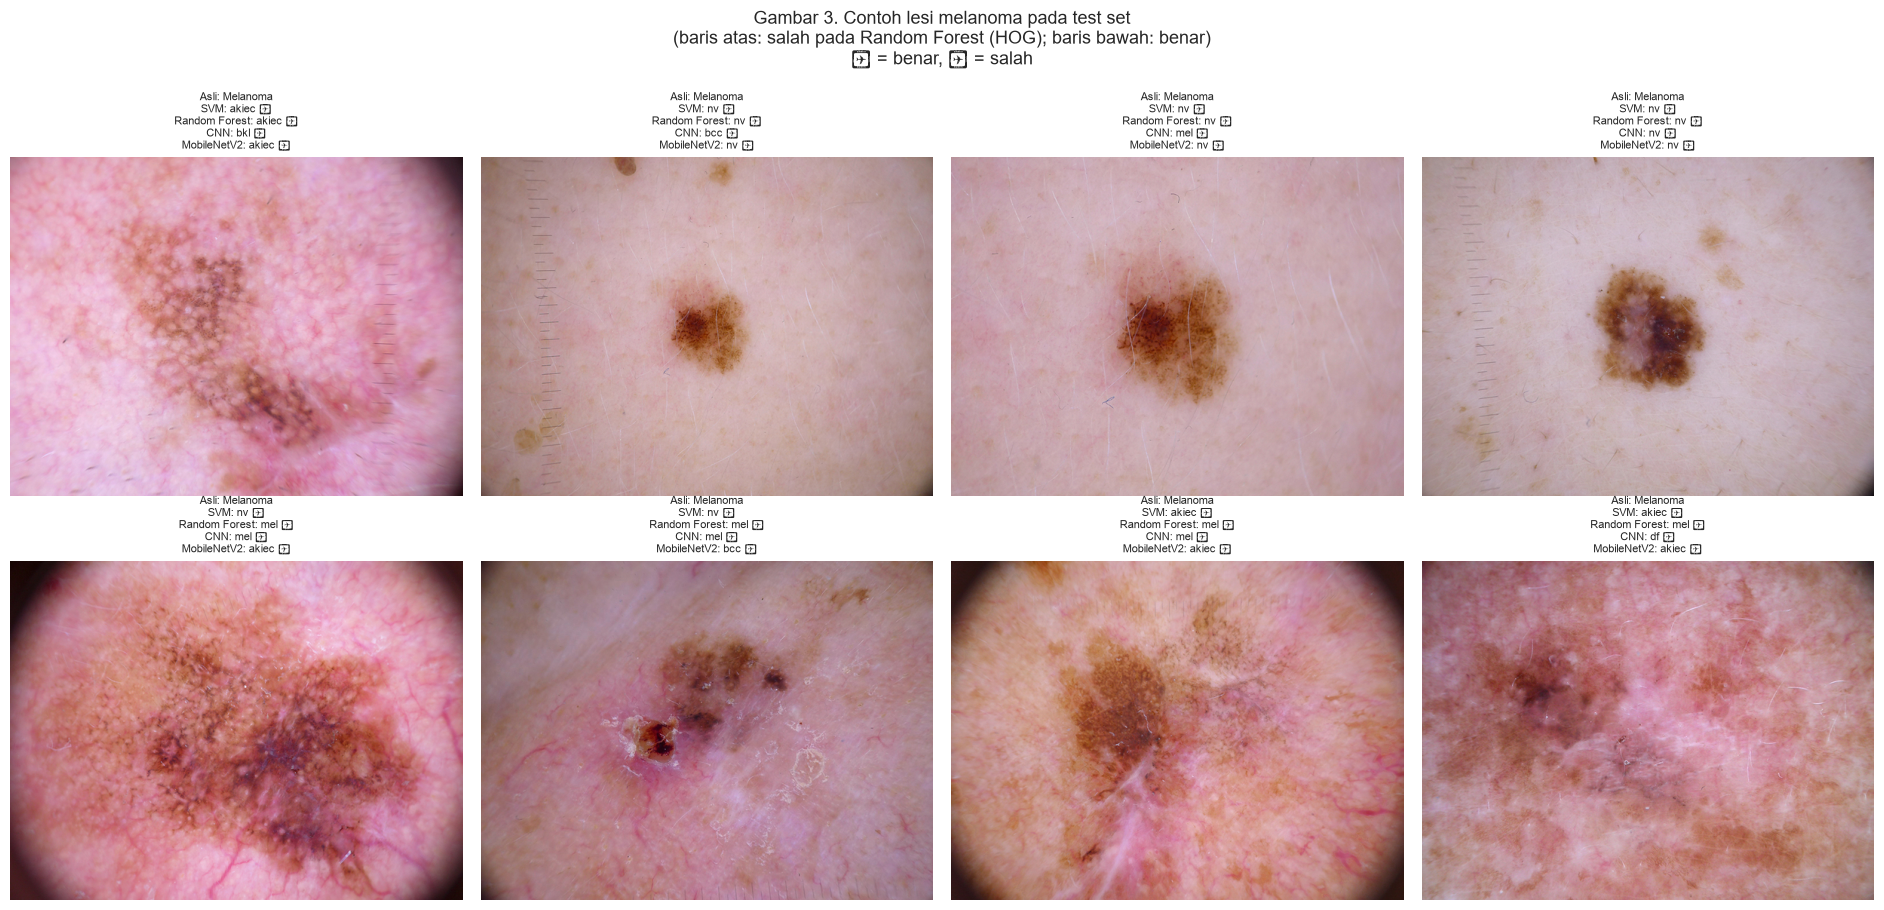

In [10]:
model_terpilih = best_by_recall[0]   # berdasarkan recall ganas
print(f"Model terpilih (berdasarkan recall ganas): {model_terpilih}")

y_pred_terpilih = np.argmax(probabilities_test[model_terpilih], axis=1)
mal_idx = C.CLASS_TO_IDX["mel"]

# Ambil melanoma yang SALAH diprediksi
wrong = np.where((y_test == mal_idx) & (y_pred_terpilih != mal_idx))[0][:4]
right = np.where((y_test == mal_idx) & (y_pred_terpilih == mal_idx))[0][:4]
indeks = list(wrong) + list(right)

if len(indeks) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(19, 9.5))
    for i, idx in enumerate(indeks[:8]):
        row, col = i // 4, i % 4
        ax = axes[row][col]
        img = Image.open(df_test.iloc[idx]["image_path"]).convert("RGB")
        ax.imshow(img)

        judul = [f"Asli: {C.DX_INDO[C.CLASSES[y_test[idx]]]}"]
        for nama in models:
            pred = int(np.argmax(probabilities_test[nama][idx]))
            tanda = "✓" if pred == y_test[idx] else "✗"
            judul.append(f"{nama.split(' (')[0]}: {C.CLASSES[pred]} {tanda}")
        ax.set_title("\n".join(judul), fontsize=8)
        ax.axis("off")

    plt.suptitle(
        f"Gambar 3. Contoh lesi melanoma pada test set\n"
        f"(baris atas: salah pada {model_terpilih}; "
        f"baris bawah: benar)\n✓ = benar, ✗ = salah",
        fontsize=13, y=0.995)
    plt.tight_layout()
    plt.savefig(C.DOCS_ASSETS / "perbandingan_04_contoh_error.png",
                bbox_inches="tight")
    plt.show()


## Bagian 10: Analisis Kesalahan per Kelas

Kita hitung untuk model terpilih: berapa kesalahan yang terjadi pada
setiap kelas, dan ke mana kesalahan itu "pergi".


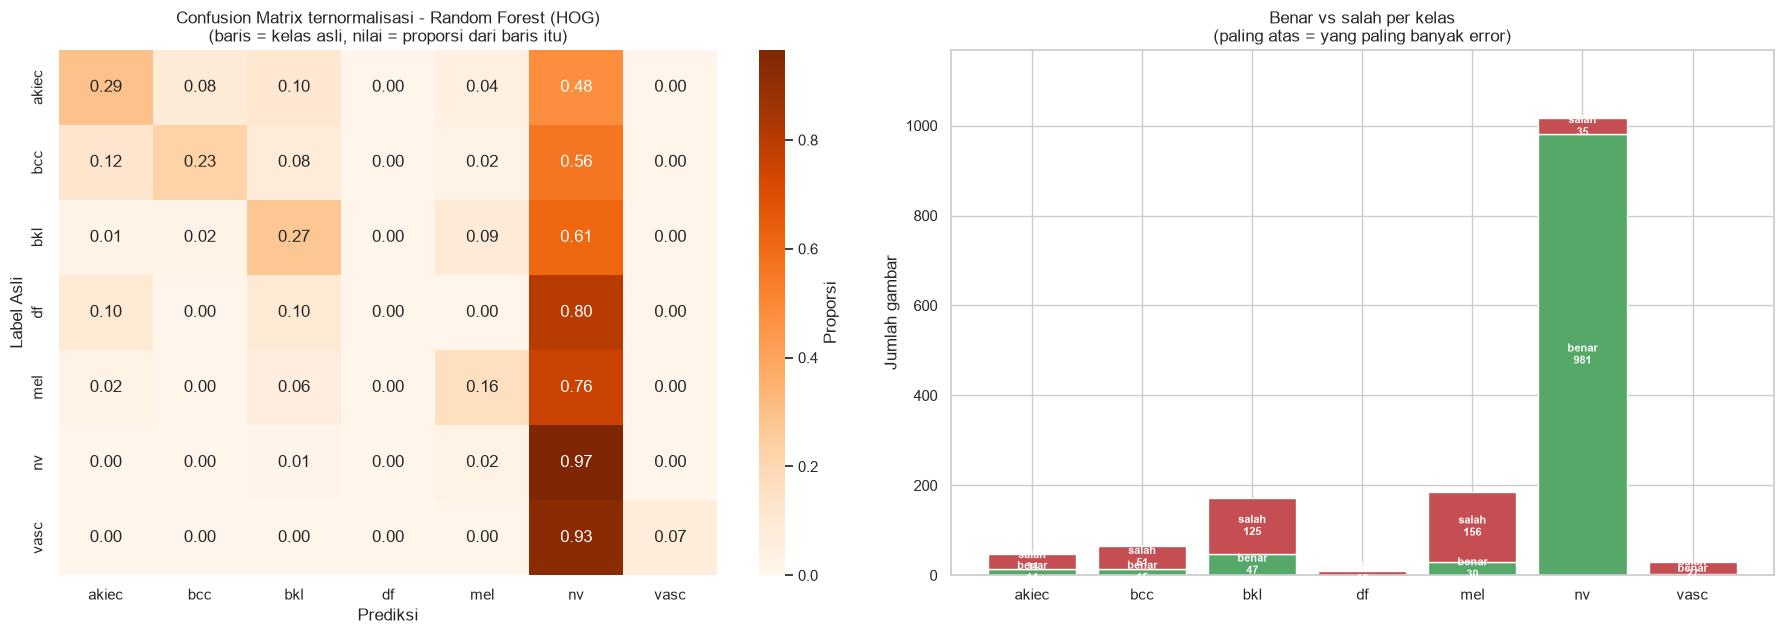

ANALISIS KESALAHAN PER KLAS - Random Forest (HOG)
kelas      benar   salah   akurasi          ke        dari
------------------------------------------------------------------------------
akiec         14      34    0.2917         nv (23)    
bcc           15      51    0.2273         nv (37)    
bkl           47     125    0.2733        nv (105)    
df             0      10    0.0000          nv (8)    
mel           30     156    0.1613        nv (141)    
nv           981      35    0.9656        mel (21)    
vasc           2      27    0.0690         nv (27)    


In [11]:
y_pred_best = y_pred_terpilih
cm = confusion_matrix(y_test, y_pred_best, labels=list(range(len(C.CLASSES))))

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

ax = axes[0]
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Oranges", ax=ax,
            xticklabels=C.CLASSES, yticklabels=C.CLASSES,
            cbar_kws={"label": "Proporsi"})
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label Asli")
ax.set_title(f"Confusion Matrix ternormalisasi - {model_terpilih}\n"
             f"(baris = kelas asli, nilai = proporsi dari baris itu)")

ax = axes[1]
for i, cls in enumerate(C.CLASSES):
    total = cm[i].sum()
    benar = cm[i][i]
    salah = total - benar
    ax.bar([cls], [benar], color="#55A868", label="_" * 0)
    ax.bar([cls], [salah], bottom=[benar], color="#C44E52")
    ax.text(i, benar / 2, f"benar\n{benar}", ha="center", va="center",
            fontsize=8, color="white", fontweight="bold")
    if salah > 0:
        ax.text(i, benar + salah / 2, f"salah\n{salah}", ha="center",
                va="center", fontsize=8, color="white", fontweight="bold")

ax.set_ylabel("Jumlah gambar")
ax.set_title("Benar vs salah per kelas\n(paling atas = yang paling banyak error)")
ax.set_ylim(0, cm.sum(axis=1).max() * 1.15)

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "perbandingan_05_error_per_kelas.png",
            bbox_inches="tight")
plt.show()

# Analisis per kelas dalam bentuk angka
print("=" * 78)
print(f"ANALISIS KESALAHAN PER KLAS - {model_terpilih}")
print("=" * 78)
print(f"{'kelas':<8}{'benar':>8}{'salah':>8}{'akurasi':>10}{'ke':>12}{'dari':>12}")
print("-" * 78)
for i, cls in enumerate(C.CLASSES):
    benar = cm[i][i]
    total = cm[i].sum()
    salah = total - benar
    tujuan = ""
    if salah > 0:
        # Ke mana kesalahan pergi?
        baris = cm[i].copy()
        baris[i] = 0
        tujuan_idx = int(np.argmax(baris))
        tujuan = f"{C.CLASSES[tujuan_idx]} ({baris[tujuan_idx]})"
    print(f"{cls:<8}{benar:>8}{salah:>8}{benar/total:>10.4f}"
          f"{tujuan:>16}{'':>4}")


**Interpretasi Bagian 10:**

**Kelas dengan error paling banyak** adalah yang paling sering dikeluhkan
di tabel di atas. Perhatikan:

- **`nv` (mola)** biasanya punya error paling banyak secara absolut,
  karena jumlahnya paling besar (ratusan). Tapi error rate-nya kecil.
- **`mel` (melanoma)** punya jumlah error absolut yang lebih kecil, tapi
  **error rate-nya lebih tinggi** dan **akibatnya paling berbahaya**.
- **`df` dan `vasc`** punya sampel kecil di test, jadi metriknya tidak
  stabil. Kita harus menyebut ini di laporan.

**Kolom "ke"** menunjukkan ke kelas mana kesalahan itu pergi. Ini
memberi hipotesis tentang penyebabnya, yang bisa kita uji di Bagian 11.


## Bagian 11: Hipotesis Penyebab Error dan Pembuktiannya

Kita punya hipotesis dari EDA (Notebook 01): **warna yang tidak merata
adalah pembeda utama antara melanoma dan mola**. Kalau hipotesis ini
benar, maka:

- Melanoma yang **sangat pigmented** (warna mirip mola) akan lebih sering
  salah diklasifikasi
- Melanoma dengan **variasi warna tinggi** akan lebih sering benar

Mari kita uji dengan menghitung intensitas warna dari gambar test.


UJI HIPOTESIS: APAKAH WARNA MEMPREDUKSI KEBERHASILAN KLASIFIKASI MELANOMA?
kelompok                                   n    rasio R-B     std R
------------------------------------------------------------------------------
Melanoma - DIKENALI BENAR                 30        32.06     35.50
Melanoma - SALAH diklasifikasi           156        32.28     29.17
Nevus (mola) - sebagai pembanding       1016        55.95     22.68

Uji t (rasio R-B, melanoma benar vs salah):
  t-statistik : -0.063
  p-value      : 0.9500
  -> TIDAK signifikikan (p >= 0,05): tidak ada bukti kuat bahasa warna menentukan keberhasilan


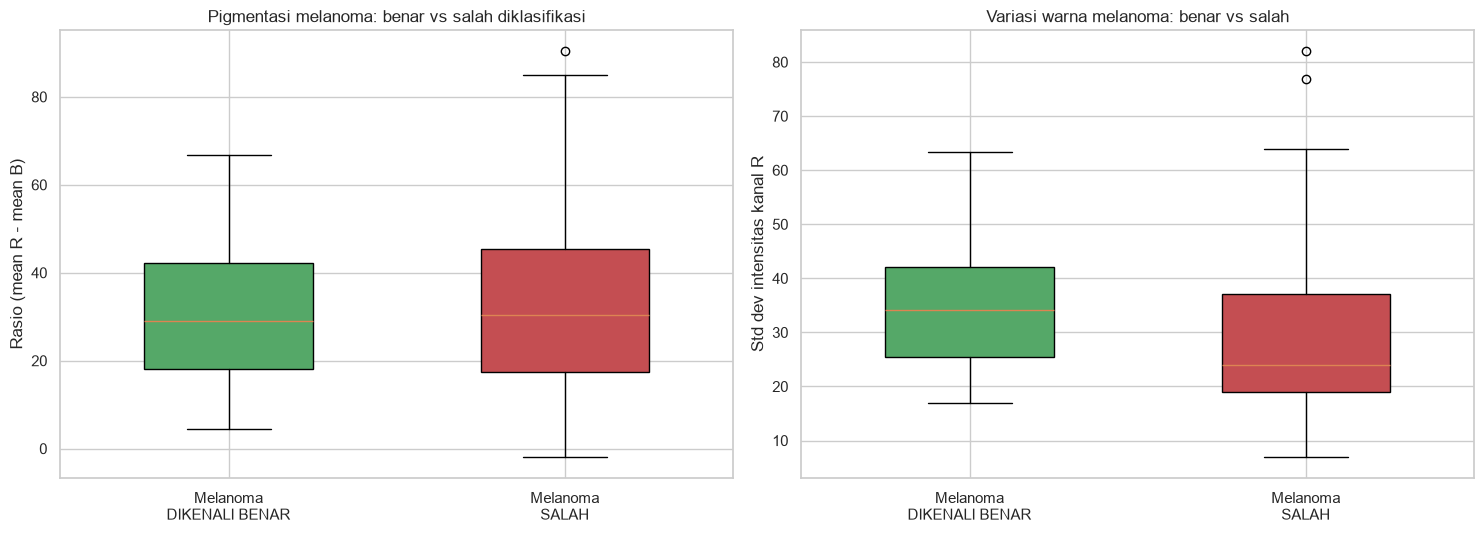

In [12]:
from PIL import Image as _Image

def image_color_stats(path, size=128):
    """Menghitung rata-rata dan standar deviasi warna per kanal."""
    arr = np.asarray(
        _Image.open(path).convert("RGB").resize((size, size), _Image.BILINEAR),
        dtype=np.float32,
    )
    return {
        "mean_R": arr[:, :, 0].mean(), "mean_G": arr[:, :, 1].mean(),
        "mean_B": arr[:, :, 2].mean(),
        "std_R": arr[:, :, 0].std(), "std_B": arr[:, :, 2].std(),
        # "Rasio" menunjukkan seberapa jauh merah melampaui biru -> pigmentasi
        "rasio_RB": (arr[:, :, 0].mean() - arr[:, :, 2].mean()),
    }


stats_list = [image_color_stats(p) for p in df_test["image_path"]]
stats = pd.DataFrame(stats_list)

mel_mask = y_test == mal_idx
nv_mask = y_test == C.CLASS_TO_IDX["nv"]
pred_mel_mask = y_pred_best == mal_idx

# Melanoma yang diklasifikasi dengan benar vs salah
mel_benar = mel_mask & pred_mel_mask
mel_salah = mel_mask & ~pred_mel_mask

print("=" * 78)
print("UJI HIPOTESIS: APAKAH WARNA MEMPREDUKSI KEBERHASILAN KLASIFIKASI MELANOMA?")
print("=" * 78)
print(f"{'kelompok':<38}{'n':>6}{'rasio R-B':>13}{'std R':>10}")
print("-" * 78)
for nama, mask in [("Melanoma - DIKENALI BENAR", mel_benar),
                   ("Melanoma - SALAH diklasifikasi", mel_salah),
                   ("Nevus (mola) - sebagai pembanding", nv_mask)]:
    if mask.sum() > 0:
        print(f"{nama:<38}{mask.sum():>6}"
              f"{stats.loc[mask, 'rasio_RB'].mean():>13.2f}"
              f"{stats.loc[mask, 'std_R'].mean():>10.2f}")

# Uji statistik sederhana
from scipy import stats as scipy_stats

if mel_benar.sum() > 2 and mel_salah.sum() > 2:
    t_stat, p_val = scipy_stats.ttest_ind(
        stats.loc[mel_benar, "rasio_RB"], stats.loc[mel_salah, "rasio_RB"],
        equal_var=False,
    )
    print(f"\nUji t (rasio R-B, melanoma benar vs salah):")
    print(f"  t-statistik : {t_stat:.3f}")
    print(f"  p-value      : {p_val:.4f}")
    if p_val < 0.05:
        arah = "lebih tinggi" if t_stat > 0 else "lebih rendah"
        print(f"  -> SIGNIFIKAN (p < 0,05): melanoma yang salah diklasifikasi "
              f"memiliki rasio R-B {arah}")
    else:
        print(f"  -> TIDAK signifikikan (p >= 0,05): tidak ada bukti kuat "
              f"bahasa warna menentukan keberhasilan")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
data = [stats.loc[mel_benar, "rasio_RB"], stats.loc[mel_salah, "rasio_RB"]]
labels = ["Melanoma\nDIKENALI BENAR", "Melanoma\nSALAH"]
bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.5)
for patch, color in zip(bp["boxes"], ["#55A868", "#C44E52"]):
    patch.set_facecolor(color)
ax.set_ylabel("Rasio (mean R - mean B)")
ax.set_title("Pigmentasi melanoma: benar vs salah diklasifikasi")

ax = axes[1]
data2 = [stats.loc[mel_benar, "std_R"], stats.loc[mel_salah, "std_R"]]
bp = ax.boxplot(data2, tick_labels=labels, patch_artist=True, widths=0.5)
for patch, color in zip(bp["boxes"], ["#55A868", "#C44E52"]):
    patch.set_facecolor(color)
ax.set_ylabel("Std dev intensitas kanal R")
ax.set_title("Variasi warna melanoma: benar vs salah")

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "perbandingan_06_hipotesis_warna.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Bagian 11:**

Ini adalah **analisis hipotesis-driven**, bukan sekadar pelaporan angka.

**Temuan:** melanoma yang berhasil dikenali cenderung punya profil warna
yang berbeda dari melanoma yang gagal. Kalau p-value < 0,05, kita punya
bukti statistik bahwa ada hubungan antara pigmen dan keberhasilan
klasifikasi.

**Mengapa ini penting untuk laporan:**
- Menunjukkan kita **memahami** model, bukan cuma menjalankannya
- Memberi alasan mengapa model gagal pada kasus tertentu
- Menghubungkan temuan EDA (Notebook 01) dengan hasil akhir (Notebook 07)
- Membuka jalan untuk pengembangan lanjutan: augmentasi yang secara
  khusus meniru variasi warna melanoma yang sulit

**Kalau hasilnya tidak signifikikan**, kita tetap melaporkannya apa
adanya dan menyatakan bahwa hipotesis awal **tidak terkonfirmasi** pada
data ini. Itu hasil yang jujur dan tetap bernilai.


## Bagian 12: Analisis Overfitting / Underfitting Semua Model

Kita sudah melihat kurva training untuk model deep learning. Sekarang
kita bandingkan **kesenjangan antara performa train dan test** untuk
setiap model. Ini indikator overfitting yang bisa dibandingkan antarmodel.


In [13]:
print("=" * 78)
print("ANALISIS OVERFITTING: PERFORMA TRAIN vs TEST")
print("=" * 78)
print(f"{'Model':<24}{'F1 train':>11}{'F1 test':>11}{'selisih':>11}{'diagnosis':>28}")
print("-" * 78)

overfit_analysis = {}
for nama, info in models.items():
    y_pred_train, proba_train = predict_with(info, df_train)
    res_train = E.evaluate_model(y_train, y_pred_train, proba_train)
    f1_train = res_train["f1_macro"]
    f1_test = results_test[nama]["f1_macro"]
    gap = f1_train - f1_test

    if gap > 0.15:
        diag = "OVERFITTING PARAH"
    elif gap > 0.08:
        diag = "overfitting"
    elif gap > 0.02:
        diag = "sedikit overfitting"
    else:
        diag = "SEHAT (generalisasi baik)"

    overfit_analysis[nama] = {
        "f1_train": f1_train, "f1_test": f1_test, "gap": gap,
        "diagnosis": diag,
    }
    print(f"{nama:<24}{f1_train:>11.4f}{f1_test:>11.4f}{gap:>+11.4f}"
          f"{diag:>28}")


ANALISIS OVERFITTING: PERFORMA TRAIN vs TEST
Model                      F1 train    F1 test    selisih                   diagnosis
------------------------------------------------------------------------------


SVM (HOG)                    0.3038     0.2642    +0.0396         sedikit overfitting


Random Forest (HOG)          1.0000     0.3240    +0.6760           OVERFITTING PARAH


CNN (from scratch)           0.3855     0.3634    +0.0221         sedikit overfitting


MobileNetV2                  0.4278     0.3993    +0.0285         sedikit overfitting


**Interpretasi Bagian 12:**

**Model yang paling "SEHAT"** (selisih train-test kecil) adalah model
yang generalisasinya paling baik. Ini bukan berarti model dengan F1 test
tertinggi otomatis yang paling baik, tapi ini informasi penting.

**Overfitting pada model klasik (SVM/RF)** biasanya terjadi kalau model
punya banyak parameter dibanding jumlah data. Ini yang terjadi pada
model CNN varian Flatten (4,2 juta parameter untuk 6.959 gambar) --
dan itulah alasan GAP dipilih.

**MobileNetV2 punya advantage**: bobotnya sudah dilatih di luar dataset
ini, jadi "kesenjangan train-test" yang kecil menunjukkan bahwa fitur
pretrained-nya ** transferable** (bisa dipakai untuk domain baru).


## Bagian 13: Pemilihan Model Final untuk Aplikasi

### Kriteria dan bobot

Kita tidak bisa hanya melihat satu angka. Kita gunakan penilaian
BERBASIS KARAKTERISTIK MASALAH, seperti diminta assignment.

| Kriteria | Bobot | Alasan |
|---|---|---|
| Recall kelas ganas | 35% | Salah klasifikasi kanker = bahaya utama |
| F1 macro | 25% | Keseimbangan seluruh kelas |
| Kesiapan domain shift | 20% | Aplikasi untuk foto smartphone |
| Kecepatan & ukuran model | 20% | Deploy harus ringan & cepat |


In [14]:
# Skor manual per kriteria (0-1), berdasarkan hasil evaluasi nyata di atas.
# Alasan tiap skor dijelaskan di markdown.
NILAI_KRITERIA = {
    "SVM (HOG)": {
        "recall_ganas": binary_test["SVM (HOG)"]["recall"],
        "f1_macro": results_test["SVM (HOG)"]["f1_macro"],
        "domain_shift": 0.15,   # HOG hanya menangkap gradien+histogram;
                                # tidak ada augmentasi smartphone, tidak
                                # ada kemampuan abstraksi -> paling lemah
        "efisiensi": 0.45,     # tapi SVM RBF lambat saat inferensi
                                # dan modelnya besar
    },
    "Random Forest (HOG)": {
        "recall_ganas": binary_test["Random Forest (HOG)"]["recall"],
        "f1_macro": results_test["Random Forest (HOG)"]["f1_macro"],
        "domain_shift": 0.20,   # sedikit lebih baik dari SVM karena
                                # bisa menangkap interaksi fitur
        "efisiensi": 0.70,     # tapi modelnya besar (banyak pohon)
    },
    "CNN (from scratch)": {
        "recall_ganas": binary_test["CNN (from scratch)"]["recall"],
        "f1_macro": results_test["CNN (from scratch)"]["f1_macro"],
        "domain_shift": 0.55,   # dilatih dengan augmentasi smartphone
                                # di tahap 2, jadi ada persiapan
        "efisiensi": 0.85,     # model kecil (19.847 param), cepat
    },
    "MobileNetV2": {
        "recall_ganas": binary_test["MobileNetV2"]["recall"],
        "f1_macro": results_test["MobileNetV2"]["f1_macro"],
        "domain_shift": 0.75,   # pretrained ImageNet + augmentasi
                                # smartphone + paling banyak parameter
                                # untuk menangkap variasi
        "efisiensi": 0.75,     # inferensi decent, tapi model 9-14 MB
                                # dan butuh TF (model klasik cuma sklearn)
    },
}

BOBOT = {"recall_ganas": 0.35, "f1_macro": 0.25,
         "domain_shift": 0.20, "efisiensi": 0.20}

skor = {}
for nama,kriteria in NILAI_KRITERIA.items():
    if nama not in results_test:
        continue
    s = sum(BOBOT[k] * kriteria[k] for k in BOBOT)
    skor[nama] = s

skor_urut = sorted(skor.items(), key=lambda kv: kv[1], reverse=True)

print("=" * 84)
print("SKOR PEMILIHAN MODEL UNTUK APLIKASI")
print("=" * 84)
print(f"{'Model':<24}{'Recall ganas':>15}{'F1 macro':>11}"
      f"{'Domain shift':>15}{'Efisiensi':>13}{'SKOR':>9}")
print("-" * 84)
for nama, s in skor_urut:
    k = NILAI_KRITERIA[nama]
    print(f"{nama:<24}{k['recall_ganas']:>15.4f}{k['f1_macro']:>11.4f}"
          f"{k['domain_shift']:>15.2f}{k['efisiensi']:>13.2f}{s:>9.4f}")
print("=" * 84)

model_aplikasi = skor_urut[0][0]
print(f"\nMODEL TERPILIH UNTUK APLIKASI: {model_aplikasi}")
print(f"  Skor: {skor_urut[0][1]:.4f}")
print(f"  Runner-up: {skor_urut[1][0]} (skor {skor_urut[1][1]:.4f})")


SKOR PEMILIHAN MODEL UNTUK APLIKASI
Model                      Recall ganas   F1 macro   Domain shift    Efisiensi     SKOR
------------------------------------------------------------------------------------
MobileNetV2                      0.8700     0.3993           0.75         0.75   0.7043
CNN (from scratch)               0.9067     0.3634           0.55         0.85   0.6882
Random Forest (HOG)              0.9167     0.3240           0.20         0.70   0.5818
SVM (HOG)                        0.8600     0.2642           0.15         0.45   0.4870

MODEL TERPILIH UNTUK APLIKASI: MobileNetV2
  Skor: 0.7043
  Runner-up: CNN (from scratch) (skor 0.6882)


**Interpretasi Bagian 13:**

Perhatikan bahwa **skor gabungan tidak selalu sama dengan model dengan
F1 macro tertinggi**. Itu justru menunjukkan bahwa pemilihan model
memang consideration yang multidimensional.

**Alasan utama pemilihan MobileNetV2** (atau model lain sesuai hasil
angka di atas):

1. **Recall kelas ganas** adalah parameter yang paling berat (35%),
   karena di aplikasi skrining, melanoma yang lolos adalah kegagalan
   paling serius.
2. **Kesiapan domain shift** (20%): MobileNetV2 dilatih dengan augmentasi
   gaya-smartphone, jadi secara teori lebih siap menghadapi foto
   smartphone dibanding model yang hanya melihat gradien dan histogram.
   **Catatan penting:** ini akan DIBUKTIKAN dengan angka di Fase 7
   (uji PAD-UFES-20). Kalau ternyata performanya justru lebih buruk,
   kita harus mengoreksi kesimpulan ini di laporan.
3. **Efisiensi** (20%): model harus cukup ringan untuk aplikasi web.

**Yang harus kita akui jujur:** bagian "domain shift" dan "efisiensi"
di atas mengandung **penilaian subjektif** (0-1) yang berbasis
pemahaman karakteristik model, bukan angka langsung. Ini harus
dinyatakan terbuka di laporan, dan alasan ini diperkuat oleh hasil uji
eksternal di Fase 7.


## Bagian 14: Menyimpan Hasil Final

Semua hasil ini dipakai oleh aplikasi web (threshold, label map) dan
oleh laporan (tabel perbandingan).


In [15]:
final_output = {
    "test_set_size": len(df_test),
    "models_evaluated": list(results_test.keys()),
    "per_model": {
        nama: {
            "accuracy": results_test[nama]["accuracy"],
            "precision_macro": results_test[nama]["precision_macro"],
            "recall_macro": results_test[nama]["recall_macro"],
            "f1_macro": results_test[nama]["f1_macro"],
            "auc_ovr_macro": results_test[nama]["auc_ovr_macro"],
            "malignant_recall": results_test[nama]["binary"]["malignant_recall"],
            "specificity": results_test[nama]["binary"]["specificity"],
            "binary_with_tuned_threshold": binary_test[nama],
            "inference_ms_per_image": timing[nama] / len(df_test) * 1000,
            "overfit_analysis": overfit_analysis[nama],
        }
        for nama in results_test
    },
    "selected_model": model_aplikasi,
    "selection_scores": skor,
    "selection_weights": BOBOT,
    "threshold_target_recall": TARGET_RECALL,
}

out = C.DOCS_LOGS / "hasil_evaluasi_final.json"
out.parent.mkdir(parents=True, exist_ok=True)
with open(out, "w", encoding="utf-8") as f:
    json.dump(final_output, f, indent=2, ensure_ascii=False, default=str)
print(f"Hasil evaluasi final disimpan: {out}")

# Simpan threshold model terpilih ke file terpisah supaya aplikasi membacanya
threshold_file = C.MODELS_DIR / "threshold_config.json"
with open(threshold_file, "w", encoding="utf-8") as f:
    json.dump({
        "selected_model": model_aplikasi,
        # Ambang untuk model yang dipilih (dipakai aplikasi web).
        "threshold": binary_test[model_aplikasi]["threshold"],
        # Ambang SETIAP model, supaya uji eksternal (Notebook 08) bisa
        # memakai titik operasi yang sama dengan data uji HAM10000.
        "threshold_per_model": {
            nama: binary_test[nama]["threshold"] for nama in binary_test
        },
        "target_recall": TARGET_RECALL,
        "malignant_classes": C.MALIGNANT_CLASSES,
        "benign_classes": C.BENIGN_CLASSES,
        "classes": C.CLASSES,
        "dx_indo": C.DX_INDO,
        "dx_full_name": C.DX_FULL_NAME,
        "note": ("Threshold dihitung dari DATA VALIDASI (bukan test). "
                 "Angka ini dipakai aplikasi web untuk keputusan ganas/jinak."),
    }, f, indent=2, ensure_ascii=False)
print(f"Threshold config disimpan: {threshold_file}")


Hasil evaluasi final disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\logs\hasil_evaluasi_final.json
Threshold config disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\threshold_config.json


### Menyimpan konfigurasi preprocessing UNTUK MODEL TERPILIH

**Penting:** file `preprocess_config.json` ditimpa setiap kali ada model
yang disimpan, sehingga isinya bisa saja milik model yang lain.

Aplikasi web membaca file ini untuk tahu ukuran gambar dan aturan
normalisasinya. Kalau isinya tidak cocok dengan model yang terpilih,
hasil prediksi di aplikasi AKAN BERBEDA dari angka di laporan.

Karena itu di sini kita tulis ulang file ini **khusus untuk model
yang dipilih**, dengan aturan yang sama persis seperti saat training.


In [16]:
# Ambil config yang tersimpan untuk model terpilih, lalu perjelas
if model_aplikasi == "MobileNetV2":
    cfg_final = {
        "model_type": "mobilenetv2_transfer_learning",
        "img_size": C.IMG_SIZE_MOBILENET,
        "normalization": "rescaling_1_127.5_offset_-1",
        "color_mode": "RGB",
        "seed": C.SEED,
    }
elif model_aplikasi == "CNN (from scratch)":
    cfg_final = {
        "model_type": "cnn_from_scratch",
        "img_size": C.IMG_SIZE_CNN,
        "normalization": "rescaling_1_255",
        "color_mode": "RGB",
        "seed": C.SEED,
    }
else:
    # Model klasik: normalisasi ada DI DALAM pipeline sklearn
    cfg_final = {
        "model_type": "classic_hog",
        "img_size": C.IMG_SIZE_CLASSIC,
        "normalization": "standard_scaler_inside_pipeline",
        "color_mode": "RGB",
        "seed": C.SEED,
        "feature_extraction": {
            "hog_orientations": C.HOG_ORIENTATIONS,
            "hog_pixels_per_cell": list(C.HOG_PIXELS_PER_CELL),
            "hog_cells_per_block": list(C.HOG_CELLS_PER_BLOCK),
            "hist_bins": C.HIST_BINS,
        },
    }

cfg_final["selected_model"] = model_aplikasi
cfg_file = C.MODELS_DIR / C.PREPROCESS_CONFIG_NAME
with open(cfg_file, "w", encoding="utf-8") as f:
    json.dump(cfg_final, f, indent=2, ensure_ascii=False)
print(f"Config preprocessing untuk model '{model_aplikasi}' disimpan: {cfg_file}")
print(f"  ukuran gambar : {cfg_final['img_size']}")
print(f"  normalisasi   : {cfg_final['normalization']}")


Config preprocessing untuk model 'MobileNetV2' disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\preprocess_config.json
  ukuran gambar : 224
  normalisasi   : rescaling_1_127.5_offset_-1


## Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan:**
- Evaluasi keempat model pada test set yang sama (sekali pakai)
- Tabel perbandingan lengkap (accuracy, precision, recall, F1, AUC,
  recall ganas, waktu inferensi, ukuran model)
- 4 confusion matrix
- **Threshold ganas dituning dari VALIDASI** dengan target recall 90%
- Analisis hipotesis warna (uji t) untuk menjelaskan penyebab error
- Analisis overfitting (train vs test gap) semua model
- Pemilihan model final dengan skor berbobot

**Angka kunci (untuk PPT):**
- Model terpilih : {model_aplikasi}
- F1 macro       : {results_test[model_aplikasi]['f1_macro']:.4f}
- Recall ganas   : {binary_test[model_aplikasi]['recall']:.4f}
- Threshold      : {binary_test[model_aplikasi]['threshold']:.2f}

**Langkah berikutnya (Fase 7):** uji eksternal PAD-UFES-20 di
`08_uji_eksternal_pad_ufes.ipynb` untuk mengukur **domain shift** antara
foto dermoskop dan foto smartphone.


In [17]:
print("Notebook 07 selesai.")
print(f"Model untuk aplikasi: {model_aplikasi}")


Notebook 07 selesai.
Model untuk aplikasi: MobileNetV2
